# Preprocessing cơ bản và EDA PM2.5

Notebook chỉ đọc mart trạm–ngày, tạo bản EDA trong bộ nhớ, xem dữ liệu rồi đề xuất giả thuyết. Không ghi đè dữ liệu, không huấn luyện model và không tự điền thiếu. PM2.5 là nhãn thô sau QC, chưa được hiệu chuẩn.

Chạy lần lượt từ trên xuống trong VS Code/Jupyter. Cần `duckdb`, `pandas`, `numpy`; biểu đồ cần `matplotlib`.

## 1. Đọc dữ liệu

Mỗi dòng đại diện cho một trạm–ngày có nhãn. Khóa là `(station_id, date_id)`; `grid_id` xác định ô lưới chứa trạm.

In [1]:
from pathlib import Path
import duckdb
import numpy as np
import pandas as pd

root = Path.cwd().resolve()
if not (root / 'data').exists():
    root = root.parent
file = root / 'data/marts/mart_station_daily_training.parquet'
if not file.exists(): raise FileNotFoundError(file)
con = duckdb.connect()
mart = con.execute('SELECT * FROM read_parquet(?)', [str(file)]).df()
print('Số dòng, số cột:', mart.shape)
print('\nVí dụ:\n', mart[['station_id','grid_id','date_id','pm25_raw_mean']].head().to_string(index=False))
print('\nCác cột:', ', '.join(mart.columns))


Số dòng, số cột: (7878, 25)

Ví dụ:
     station_id             grid_id  date_id  pm25_raw_mean
openaq_2161293 grid_573000_2313000 20240110          41.65
openaq_2161293 grid_573000_2313000 20241003          24.29
openaq_2161293 grid_573000_2313000 20241004          35.45
openaq_2161293 grid_573000_2313000 20241005          44.34
openaq_2161293 grid_573000_2313000 20241006          47.68

Các cột: station_id, grid_id, date_id, pm25_raw_mean, date, month, day_of_week, is_weekend, hanoi_season, temp_2m_mean_c, dewpoint_2m_mean_c, rh_mean_pct, precip_daily_mm, wind_speed_scalar_ms, wind_persistence, surface_pressure_hpa, blh_mean_m, blh_min_m, no2_tropospheric_mol_m2, co_column_mol_m2, o3_column_mol_m2, so2_column_mol_m2, aod_047_mean, is_aod_missing_mnar, viirs_nightlight_rad


## 2. Kiểm tra dữ liệu

Kiểm tra khóa và tỷ lệ thiếu trước khi xử lý. Không tự xóa dòng trùng hay thay `NULL` bằng 0.

In [2]:
keys = ['station_id', 'date_id']
print('Dòng có khóa thiếu:', int(mart[keys].isna().any(axis=1).sum()))
print('Dòng có khóa trùng:', int(mart.duplicated(keys, keep=False).sum()))
assert not mart[keys].isna().any().any(), 'Khóa thiếu'
assert not mart.duplicated(keys).any(), 'Khóa trùng; cần điều tra'
missing = pd.DataFrame({'so_null':mart.isna().sum(), 'ty_le_null_%':(mart.isna().mean()*100).round(2)})
print('\nCác cột thiếu:\n', missing[missing.so_null>0].sort_values('ty_le_null_%',ascending=False).to_string())


Dòng có khóa thiếu: 0
Dòng có khóa trùng: 0

Các cột thiếu:
                          so_null  ty_le_null_%
blh_mean_m                  7878        100.00
blh_min_m                   7878        100.00
aod_047_mean                6707         85.14
no2_tropospheric_mol_m2     5608         71.19
so2_column_mol_m2           5580         70.83
co_column_mol_m2            4518         57.35
viirs_nightlight_rad         602          7.64
o3_column_mol_m2              61          0.77


## 3. Preprocessing thô cho EDA

Giữ dòng có nhãn, kiểm tra ngày. Cột số giữ nguyên; cột chữ như mùa được mã hóa 0/1. Không đưa mã trạm, ô hoặc ngày vào ma trận vì đó là khóa. Cột toàn thiếu hoặc không thay đổi không tính được tương quan và chỉ bị loại khỏi bản ma trận, không xóa khỏi mart.

In [3]:
eda = mart.loc[mart.pm25_raw_mean.notna()].copy()
print('Dòng không có nhãn:', len(mart)-len(eda))
eda['ngay'] = pd.to_datetime(eda.date_id.astype(str),format='%Y%m%d',errors='coerce')
assert eda.ngay.notna().all(), 'Ngày không hợp lệ'
eda['nam'] = eda.ngay.dt.year
exclude = ['station_id','grid_id','date_id','date']
features = mart.drop(columns=[c for c in exclude if c in mart.columns]).loc[eda.index].copy()
numbers = features.select_dtypes(include=['number','bool']).astype(float)
categories = features.select_dtypes(include=['object','string','category'])
other = set(features.columns)-set(numbers.columns)-set(categories.columns)
if other: raise ValueError(f'Kiểu chưa hỗ trợ: {sorted(other)}')
print('Khóa/ngày không tính tương quan:',exclude)
print('Cột chữ cần mã hóa:',categories.columns.tolist())
parts = [numbers]
for col in categories.columns:
    values = categories[col].astype('string')
    if values.nunique(dropna=True)>30: raise ValueError(f'Cần kiểm tra nhiều loại trong {col}')
    one_hot = pd.get_dummies(values,prefix=col,dtype=float)
    one_hot.loc[values.isna(),:] = np.nan
    parts.append(one_hot)
numeric = pd.concat(parts,axis=1)
print('Giá trị vô hạn chuyển thành thiếu trong bản EDA:',int(np.isinf(numeric.to_numpy()).sum()))
numeric = numeric.replace([np.inf,-np.inf],np.nan)
unusable = numeric.columns[numeric.nunique(dropna=True)<2].tolist()
print('Không tính tương quan vì toàn thiếu hoặc không đổi:',unusable)
numeric = numeric.drop(columns=unusable)
columns = list(numeric.columns)
print('Các cột tính tương quan:',columns)


Dòng không có nhãn: 0
Khóa/ngày không tính tương quan: ['station_id', 'grid_id', 'date_id', 'date']
Cột chữ cần mã hóa: ['hanoi_season']
Giá trị vô hạn chuyển thành thiếu trong bản EDA: 0
Không tính tương quan vì toàn thiếu hoặc không đổi: ['blh_mean_m', 'blh_min_m']
Các cột tính tương quan: ['pm25_raw_mean', 'month', 'day_of_week', 'is_weekend', 'temp_2m_mean_c', 'dewpoint_2m_mean_c', 'rh_mean_pct', 'precip_daily_mm', 'wind_speed_scalar_ms', 'wind_persistence', 'surface_pressure_hpa', 'no2_tropospheric_mol_m2', 'co_column_mol_m2', 'o3_column_mol_m2', 'so2_column_mol_m2', 'aod_047_mean', 'is_aod_missing_mnar', 'viirs_nightlight_rad', 'hanoi_season_Autumn', 'hanoi_season_Spring', 'hanoi_season_Summer', 'hanoi_season_Winter']


## 4. EDA: độ phủ và phân phối nhãn

Trạm xuất hiện nhiều ngày, nên số trạm–ngày không phải số trạm độc lập. Các mùa có thể gồm những trạm và năm khác nhau.

In [4]:
print('Trạm:',eda.station_id.nunique(),'| ô có nhãn:',eda.grid_id.nunique())
coverage = eda.groupby('nam').agg(tram_ngay=('station_id','size'),tram=('station_id','nunique'),o=('grid_id','nunique'))
print('\nĐộ phủ theo năm:\n',coverage.to_string())
print('\nThống kê PM2.5:\n',eda.pm25_raw_mean.describe(percentiles=[.25,.5,.75,.95]).round(2).to_string())
by_season = eda.groupby('hanoi_season').agg(so_dong=('station_id','size'),trung_binh=('pm25_raw_mean','mean'),trung_vi=('pm25_raw_mean','median'))
print('\nPM2.5 theo mùa:\n',by_season.round(2).to_string())


Trạm: 39 | ô có nhãn: 36

Độ phủ theo năm:
       tram_ngay  tram   o
nam                      
2021        351     1   1
2022        293     1   1
2023        284     1   1
2024       5024    35  32
2025       1926    18  18

Thống kê PM2.5:
 count    7878.00
mean       37.59
std        25.74
min         0.00
25%        20.30
50%        30.79
75%        47.38
95%        88.30
max       293.29

PM2.5 theo mùa:
               so_dong  trung_binh  trung_vi
hanoi_season                               
Autumn           1228       31.92     28.17
Spring           1442       38.85     35.28
Summer           2202       23.27     20.66
Winter           3006       49.79     42.84


## 5. EDA: vệ tinh thiếu bao nhiêu?

Tỷ lệ tính trên trạm–ngày có nhãn; khác tỷ lệ trên toàn lưới. `NULL` không chứng minh nguyên nhân thiếu hay cơ chế MNAR.

In [5]:
sat = ['aod_047_mean','no2_tropospheric_mol_m2','co_column_mol_m2','o3_column_mol_m2','so2_column_mol_m2','viirs_nightlight_rad']
print(missing.loc[sat].sort_values('ty_le_null_%',ascending=False).to_string())
both = eda.aod_047_mean.isna() & eda.no2_tropospheric_mol_m2.isna()
print('\nThiếu cả AOD và NO₂:',int(both.sum()),'/',len(eda),'=',round(100*both.mean(),2),'%')
print('\nAOD thiếu theo mùa (%):\n',eda.groupby('hanoi_season')['aod_047_mean'].agg(so_dong='size',ty_le_null=lambda x: round(100*x.isna().mean(),2)).to_string())


                         so_null  ty_le_null_%
aod_047_mean                6707         85.14
no2_tropospheric_mol_m2     5608         71.19
so2_column_mol_m2           5580         70.83
co_column_mol_m2            4518         57.35
viirs_nightlight_rad         602          7.64
o3_column_mol_m2              61          0.77

Thiếu cả AOD và NO₂: 5514 / 7878 = 69.99 %

AOD thiếu theo mùa (%):
               so_dong  ty_le_null
hanoi_season                     
Autumn           1228   84.279999
Spring           1442   84.809998
Summer           2202   98.269997
Winter           3006   76.010002


## 6. EDA: ma trận tương quan

Pearson được tính cho từng cặp có giá trị thực; bảng số mẫu đi kèm vì mỗi cặp có thể có lượng dữ liệu khác nhau. Không điền trung vị trước khi tính. Hệ số không chứng minh nhân quả; `day_of_week` là chu kỳ, cờ mùa loại trừ nhau và các dòng lặp theo trạm. `is_aod_missing_mnar` chỉ được hiểu là cờ AOD thiếu.

In [6]:
correlation = numeric.corr(method='pearson',min_periods=2)
observed = numeric.notna().astype('int64')
pair_counts = observed.T.dot(observed)
print('Ma trận Pearson:\n',correlation.round(2).to_string())
print('\nSố quan sát từng cặp:\n',pair_counts.to_string())
summary = pd.DataFrame({'tuong_quan_PM25':correlation['pm25_raw_mean'], 'so_cap':pair_counts['pm25_raw_mean']})
print('\nSo với PM2.5:\n',summary.round(3).to_string())


Ma trận Pearson:
                          pm25_raw_mean  month  day_of_week  is_weekend  temp_2m_mean_c  dewpoint_2m_mean_c  rh_mean_pct  precip_daily_mm  wind_speed_scalar_ms  wind_persistence  surface_pressure_hpa  no2_tropospheric_mol_m2  co_column_mol_m2  o3_column_mol_m2  so2_column_mol_m2  aod_047_mean  is_aod_missing_mnar  viirs_nightlight_rad  hanoi_season_Autumn  hanoi_season_Spring  hanoi_season_Summer  hanoi_season_Winter
pm25_raw_mean                     1.00   0.02        -0.03       -0.03           -0.31               -0.35        -0.27            -0.24                 -0.23             -0.24                  0.32                     0.36              0.30             -0.35               0.11          0.20                -0.27                  0.09                -0.09                 0.02                -0.35                 0.37
month                             0.02   1.00         0.01        0.02            0.21                0.13        -0.09             0.06      

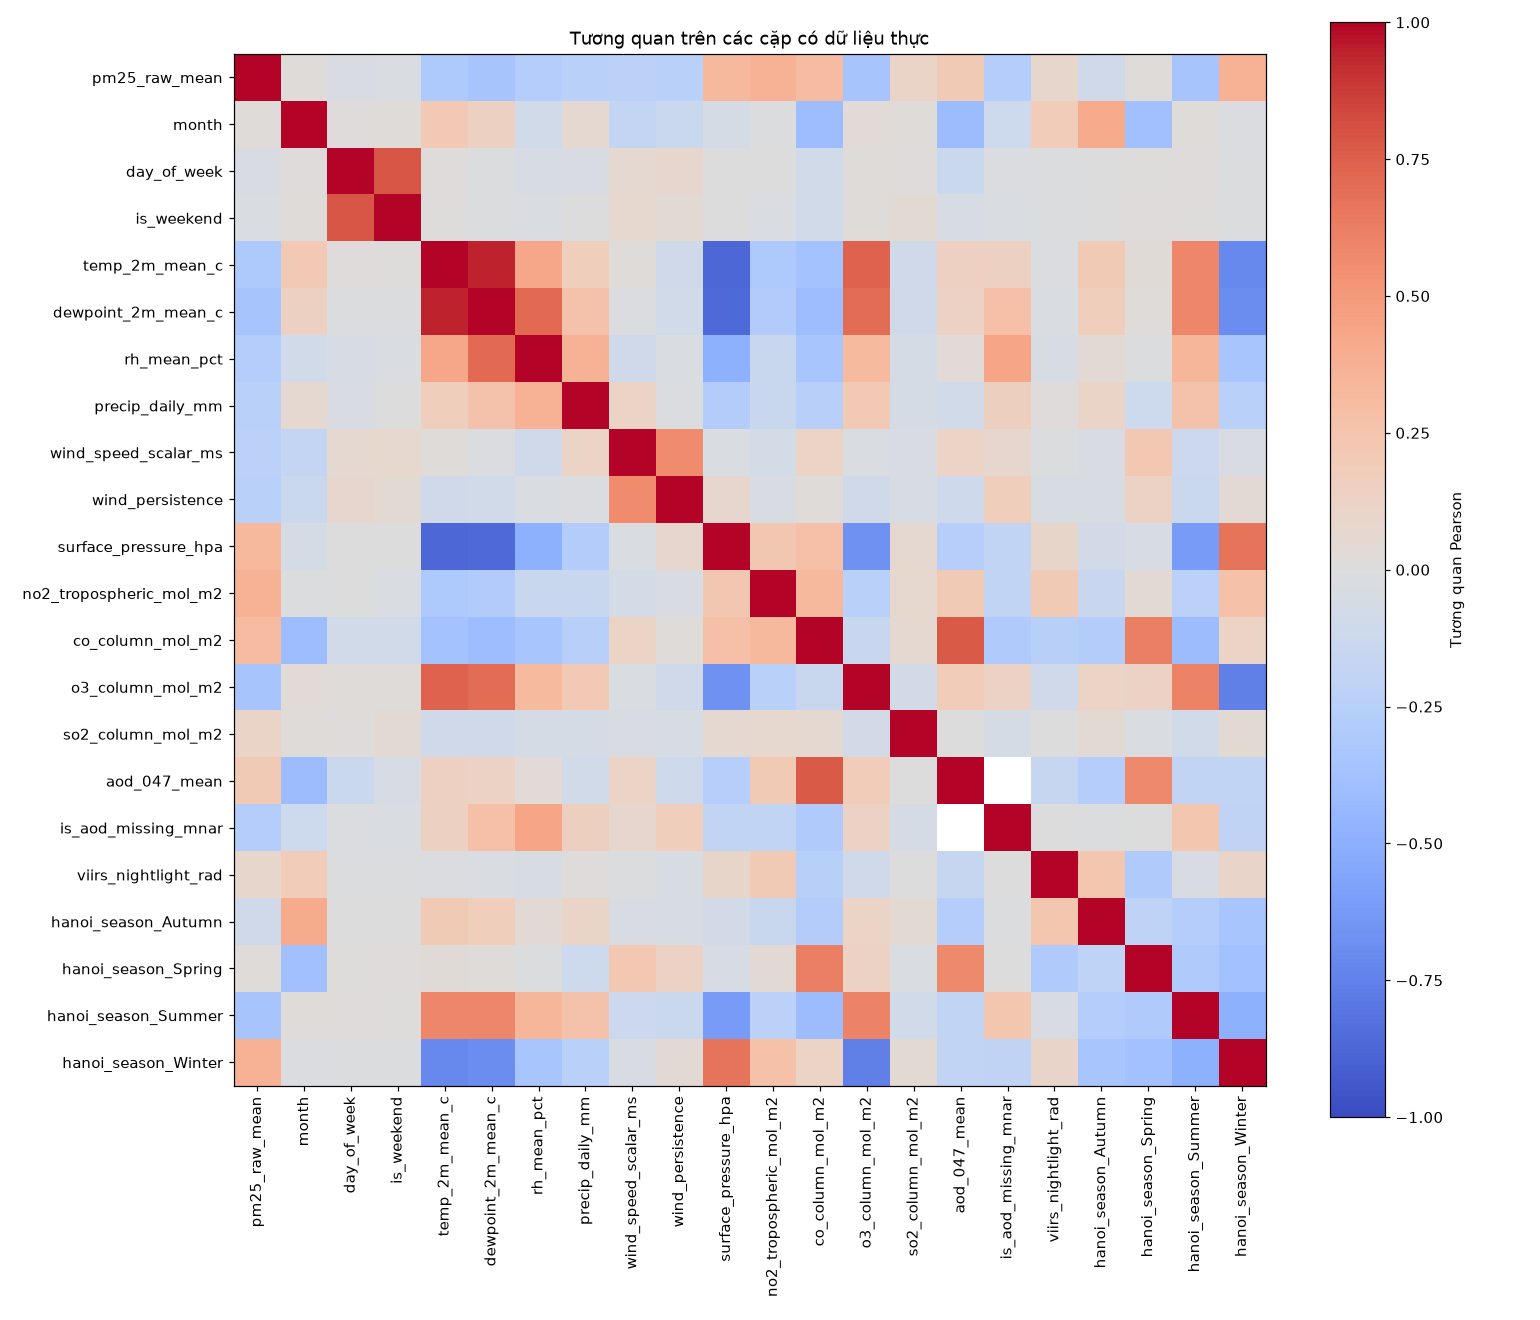

In [7]:
try:
    import matplotlib.pyplot as plt
except ImportError:
    print('Cần matplotlib để vẽ; bảng tương quan ở ô trước vẫn sử dụng được.')
else:
    fig, ax = plt.subplots(figsize=(14,12))
    image = ax.imshow(correlation.to_numpy(),cmap='coolwarm',vmin=-1,vmax=1)
    ax.set_xticks(range(len(columns)),columns,rotation=90)
    ax.set_yticks(range(len(columns)),columns)
    fig.colorbar(image,ax=ax,label='Tương quan Pearson')
    ax.set_title('Tương quan trên các cặp có dữ liệu thực')
    plt.tight_layout()
    plt.show()


## 7. Giả thuyết đề xuất sau EDA — chưa kiểm chứng

| Câu hỏi | Quan sát để bắt đầu | Cách kiểm chứng tiếp |
|---|---|---|
| Độ phủ trạm có khác nhau theo năm và khu vực? | Xem bảng theo năm ở mục 4. | Đếm trạm/ô theo tháng và vẽ vị trí trạm; xem H1 trong analysis plan. |
| Nhãn từ ít giờ có đại diện cho cả ngày không? | Mart không chứa số giờ; chưa thể kết luận ở đây. | Tái lập QC giờ, lấy bớt giờ trong cùng ngày đủ 24 giờ và so sánh. |
| Các trạm cùng ô–ngày có giống nhau không? | Một ô–ngày có thể có nhiều dòng trạm. | Ghép fact theo ô–ngày, so sánh từng cặp và các giờ chung. |
| AOD/NO₂ thiếu khác nhau theo mùa và trạm không? | Xem bảng null ở mục 5. | Tính tỷ lệ theo năm, mùa, trạm và trên toàn lưới; không kết luận MNAR từ tỷ lệ thiếu. |
| BLH có cải thiện mối liên hệ AOD–PM2.5 không? | BLH hiện toàn NULL. | Chờ TV3, so sánh AOD với AOD/BLH trên cùng mẫu hợp lệ. |

Kiểm chứng từng giả thuyết theo [analysisplan.md](../docs/analysisplan.md), ghi số mẫu và giới hạn. Trước khi train, chia dữ liệu rồi mới fit bước điền thiếu hoặc mã hóa; notebook này không tạo tập train/test.